# PMData dataset and target audit

Reproduces the audit from the unmodified supplied ZIP or an extracted directory. No models are trained. A trusted local scan cache avoids rereading all sensor measurements; removing that cache triggers a fresh scan. See README_AUDIT.md for assumptions, dependency installation and execution instructions. Derived participant outputs remain local.

The timezone offsets are sensitivity scenarios. Counts cannot certify true local-cutoff availability because device timezone and report ingestion logs are absent.

In [1]:
from pathlib import Path
import sys, os, json
ROOT=Path.cwd()
if ROOT.name == 'notebooks': ROOT=ROOT.parent
assert (ROOT/'scripts/audit_pmdata.py').exists()
sys.path.insert(0,str(ROOT/'scripts'))
import audit_pmdata
manifest=ROOT/'reports/audit_run.json'
previous=json.loads(manifest.read_text(encoding='utf-8')) if manifest.exists() else {}
raw=os.environ.get('PMDATA_INPUT',previous.get('input_path',str(ROOT/'data/raw/pmdata')))
result=audit_pmdata.main(['--input',raw,'--reuse-scan'])
print('Input SHA256:',result.get('archive_sha256'))
print('Raw reports/episodes:',result['wellness_reports'],result['sleep_episodes'])

Reused local scan cache


{
  "wellness_reports": 1747,
  "sleep_episodes": 2064,
  "eligible_sleep_targets": 1840,
  "participants": 16,
  "effective_sample_sizes": [
    {
      "offset_hours": 0,
      "feature_requirement": "sleep_history_only",
      "cognitive_samples": 1468,
      "positive_labels": 482,
      "negative_labels": 986,
      "cognitive_participants": 16,
      "sleep_samples": 1704,
      "sleep_participants": 15
    },
    {
      "offset_hours": 0,
      "feature_requirement": "sleep_and_wellness",
      "cognitive_samples": 1253,
      "positive_labels": 417,
      "negative_labels": 836,
      "cognitive_participants": 16,
      "sleep_samples": 1376,
      "sleep_participants": 15
    },
    {
      "offset_hours": 0,
      "feature_requirement": "sleep_and_rhr",
      "cognitive_samples": 1194,
      "positive_labels": 389,
      "negative_labels": 805,
      "cognitive_participants": 14,
      "sleep_samples": 1421,
      "sleep_participants": 14
    },
    {
      "offset_hours": 0

Input SHA256: 53a49d94a2e9713fb8a0fc57d4d9dec3e1e4d2ae866969cd1f7537a5bc125357
Raw reports/episodes: 1747 2064


In [2]:
import pandas as pd
inventory=pd.read_csv(ROOT/'research/dataset_inventory.csv')
coverage=pd.read_csv(ROOT/'reports/participant_coverage.csv')
effective=pd.read_csv(ROOT/'reports/effective_sample_sizes.csv')
display(inventory.groupby(['source_file','status'],dropna=False).records.sum().reset_index())
display(coverage)
display(effective)
display(pd.read_csv(ROOT/'reports/quality_check_summary.csv'))

,source_file,status,records
0,fitbit/calories.json,ok,3377529
1,fitbit/distance.json,ok,1534705
2,fitbit/exercise.json,ok,2440
3,fitbit/heart_rate.json,ok,20991392
4,fitbit/lightly_active_minutes.json,missing,0
...,...,...,...
619,participant-overview.xlsx,ok,16
620,pmsys/injury.csv,missing,0
621,pmsys/injury.csv,ok,225
622,pmsys/srpe.csv,ok,783


,participant_id,total_observation_days,study_window_days,wellness_days,sleep_days,physiological_data_days,heart_rate_days,activity_data_days,overlapping_observation_days,missing_all_modality_days,missing_wellness_days,missing_sleep_days,valid_next_day_fatigue_prediction_samples,valid_next_night_sleep_prediction_samples,positive_fatigue_labels,negative_fatigue_labels,all_modal_fatigue_samples,all_modal_sleep_samples
0,p01,152,152,138,150,152,152,152,137,0,14,2,134.0,147.0,57.0,77.0,123.0,135.0
1,p02,152,152,99,142,89,148,148,56,0,53,10,93.0,135.0,2.0,91.0,36.0,53.0
2,p03,152,152,78,78,101,119,120,45,0,74,74,41.0,55.0,2.0,39.0,28.0,34.0
3,p04,152,152,144,144,35,146,147,33,0,8,8,134.0,138.0,49.0,85.0,30.0,32.0
4,p05,152,152,134,118,86,145,144,61,0,18,34,104.0,99.0,25.0,79.0,53.0,53.0
5,p06,152,152,147,150,150,152,152,146,0,5,2,144.0,146.0,47.0,97.0,141.0,143.0
6,p07,148,152,132,142,144,147,147,127,4,20,10,126.0,136.0,24.0,102.0,116.0,125.0
7,p08,143,152,103,133,139,139,139,94,9,49,19,94.0,125.0,53.0,41.0,71.0,88.0
8,p09,152,152,102,136,147,151,150,94,0,50,16,93.0,118.0,36.0,57.0,74.0,83.0
9,p10,148,152,95,99,110,114,113,80,4,57,53,82.0,87.0,59.0,23.0,69.0,73.0


,offset_hours,feature_requirement,cognitive_samples,positive_labels,negative_labels,cognitive_participants,sleep_samples,sleep_participants
0,0,sleep_history_only,1468,482,986,16,1704,15
1,0,sleep_and_wellness,1253,417,836,16,1376,15
2,0,sleep_and_rhr,1194,389,805,14,1421,14
3,0,sleep_and_activity,1466,481,985,16,1702,15
4,0,all_four,1017,335,682,14,1132,14
5,1,sleep_history_only,1465,480,985,16,1704,15
6,1,sleep_and_wellness,1242,413,829,16,1373,15
7,1,sleep_and_rhr,1193,389,804,14,1421,14
8,1,sleep_and_activity,1463,479,984,16,1702,15
9,1,all_four,1011,335,676,14,1132,14


,check,count
0,sleep_nonpositive_elapsed,0
1,sleep_tst_exceeds_elapsed,0
2,sleep_duration_ms_mismatch_gt_1_min,0
3,sleep_tib_mismatch_gt_1_min,0
4,sleep_efficiency_outside_0_100,0
5,sleep_efficiency_diff_from_tst_over_tib_gt_5_p...,1472
6,sleep_tst_below_180_or_above_720,35
7,hr_outside_25_220_bpm,0
8,hr_confidence_zero,257376
9,zero_step_days,10


## Integrity checks

These checks verify meaningful temporal and count invariants: no next-available-row substitution across gaps; every sleep label follows its cutoff within the declared following-night window; eligibility denominators agree; and next-day labels do not cross validation boundaries. They are independent checks of generated outputs, not fitted-model tests.

In [3]:
import datetime as dt
samples=pd.read_csv(ROOT/'reports/prediction_sample_eligibility.csv')
base=samples[samples.offset_hours.eq(0)]
reference=effective[(effective.offset_hours.eq(0)) & effective.feature_requirement.eq('sleep_history_only')].iloc[0]
assert len(base)==16*152
assert int((base.sleep_history & base.fatigue_label.notna()).sum())==reference.cognitive_samples
assert int((base.sleep_history & base.sleep_target_valid).sum())==reference.sleep_samples
assert coverage.valid_next_day_fatigue_prediction_samples.sum()==reference.cognitive_samples
assert coverage.valid_next_night_sleep_prediction_samples.sum()==reference.sleep_samples
assert base.loc[base.fatigue_label.notna(),'fatigue_label'].between(1,5).all()
assert (base.loc[base.fatigue_label.notna(),'elevated_fatigue'].astype(int)==(base.loc[base.fatigue_label.notna(),'fatigue_label']<=2).astype(int)).all()
episodes=pd.read_csv(ROOT/'reports/sleep_episode_audit.csv')
episodes['logId']=episodes.logId.astype(str)
episode_lookup={(r.participant_id,str(r.logId)):r for r in episodes.itertuples()}
for r in base[base.sleep_target_valid].itertuples():
    episode=episode_lookup[(r.participant_id,str(int(float(r.target_sleep_log_id))))]
    start=dt.datetime.fromisoformat(episode.startTime)
    cutoff=dt.datetime.combine(dt.date.fromisoformat(r.cutoff_date),dt.time(20))
    assert cutoff < start < cutoff+dt.timedelta(hours=16)
    assert episode.mainSleep
    assert 0 < episode.minutesAsleep <= episode.elapsed_minutes+1
splits=pd.read_csv(ROOT/'reports/validation_split_audit.csv')
assert not splits.empty
for task,label in [('fatigue','fatigue_label'),('sleep','sleep_target_minutes')]:
    valid=base[base.sleep_history & base[label].notna() & ~base.cutoff_date.isin(['2020-01-31','2020-02-29'])].copy()
    valid['split']=valid.cutoff_date.map(lambda d:'train' if d<'2020-02-01' else 'validation' if d<'2020-03-01' else 'test')
    for (person,part),g in valid.groupby(['participant_id','split']):
        expected=splits[(splits.task==task)&(splits.participant_id==person)&(splits.split==part)].iloc[0]
        assert len(g)==expected.n
        for d in g.cutoff_date:
            next_day=(dt.date.fromisoformat(d)+dt.timedelta(days=1)).isoformat()
            assert (next_day<'2020-02-01') if part=='train' else (next_day<'2020-03-01') if part=='validation' else True
print('Eligibility, cutoff windows, target coding, and count invariants passed.')

Eligibility, cutoff windows, target coding, and count invariants passed.


In [4]:
import zipfile,io
if Path(raw).is_file():
    with zipfile.ZipFile(raw) as z:
        metadata=pd.read_excel(io.BytesIO(z.read('participant-overview.xlsx')),header=1)
else:
    metadata=pd.read_excel(Path(raw)/'participant-overview.xlsx',header=1)
display(metadata)
display(metadata.Age.describe())
display(pd.read_csv(ROOT/'reports/validation_split_audit.csv').groupby(['task','split'])[['n','positive','negative']].sum())
display(pd.read_csv(ROOT/'reports/subject_holdout_audit.csv'))

,Participant ID,Age,Height,Gender,A or B person,Max heart rate,Date,Minutes,Seconds,Stride walk,Stride run
0,p01,48,195,male,A,182,2019-11-26 00:00:00,29,33,80.90,102.9
1,p02,60,180,male,A,169,2019-12-15 00:00:00,23,51,74.70,92.4
2,p03,25,184,male,A,157,2019-12-30 00:00:00,33,22,NaN,NaN
3,p04,26,163,female,A,195,2019-11-19 00:00:00,22,13,67.30,110.2
4,p05,35,176,male,A,184,2019-12-23 00:00:00,32,40,73.00,94.3
5,p06,42,179,male,B,181,2019-12-01 00:00:00,23,19,73.04,97.6
6,p07,26,177,male,B,NaN,2019-11-19 00:00:00,19,40,73.50,119.5
7,p08,27,186,male,B,200,2019-11-28 00:00:00,18,47,77.20,103.6
8,p09,26,180,male,B,183,2020-01-07 00:00:00,35,6,74.70,109.9
9,p10,38,179,female,B,197,2019-12-08 00:00:00,28,10,73.09,102.3


count    16.000000
mean     34.875000
std      11.672618
min      23.000000
25%      26.000000
50%      29.000000
75%      42.750000
max      60.000000
Name: Age, dtype: float64

n  positive  negative
task    split                               
fatigue test         228      49.0     179.0
        train        934     328.0     606.0
        validation   287      98.0     189.0
sleep   test         297       0.0       0.0
        train       1057       0.0       0.0
        validation   329       0.0       0.0

,participant_id,deterministic_group_fold,fatigue_n,positive,negative,sleep_n,fatigue_categories
0,p01,0,134,57,77,147,4
1,p02,1,93,2,91,135,2
2,p03,2,41,2,39,55,3
3,p04,3,134,49,85,138,4
4,p05,0,104,25,79,99,3
5,p06,1,144,47,97,146,4
6,p07,2,126,24,102,136,4
7,p08,3,94,53,41,125,4
8,p09,0,93,36,57,118,5
9,p10,1,82,59,23,87,4


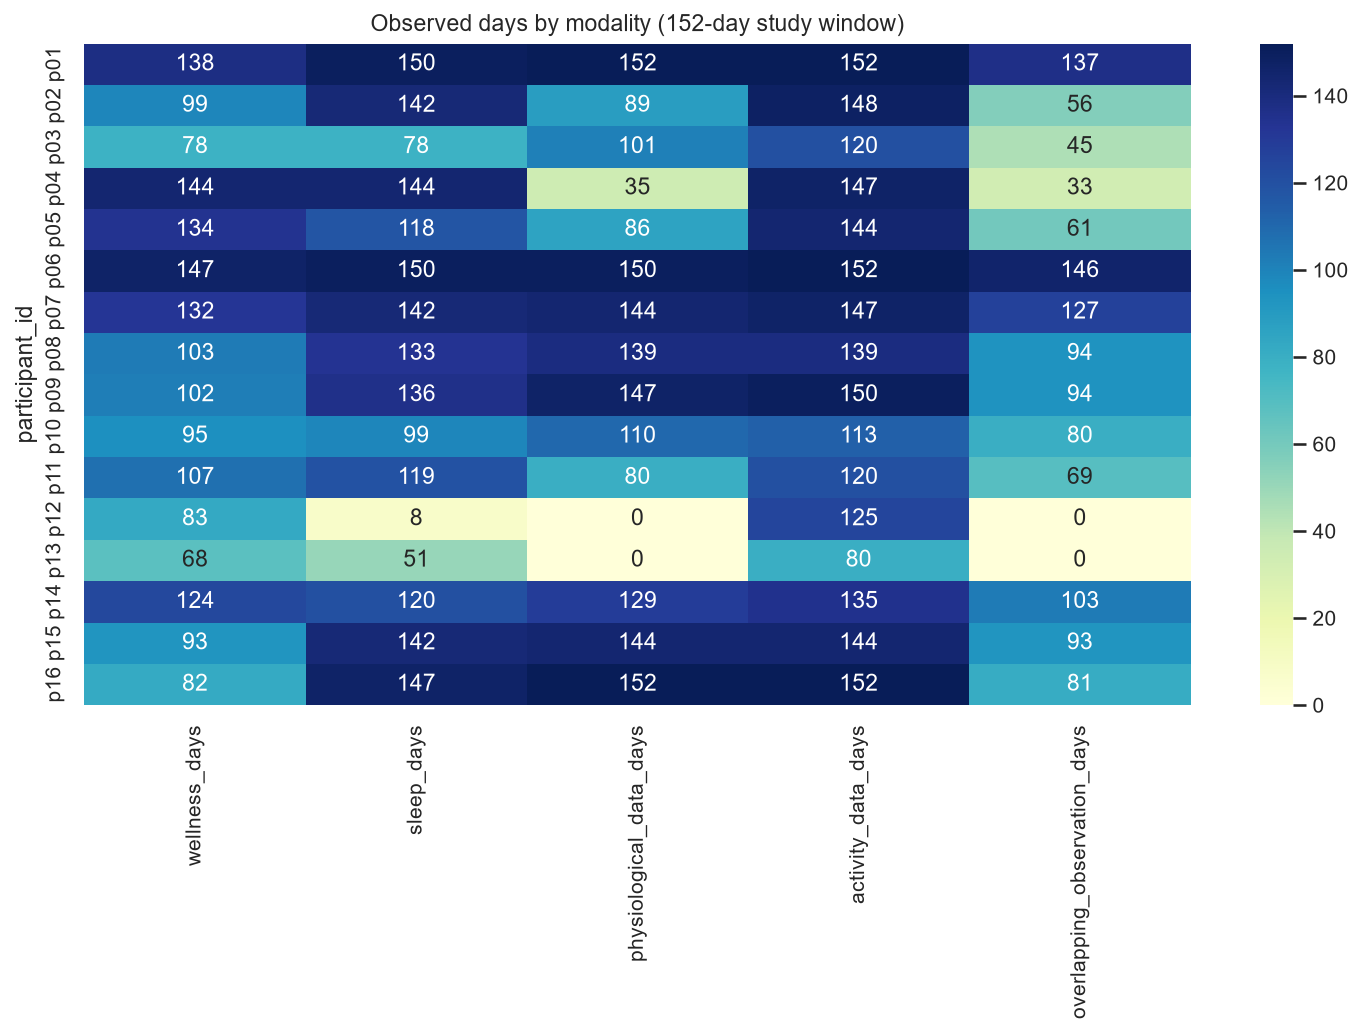

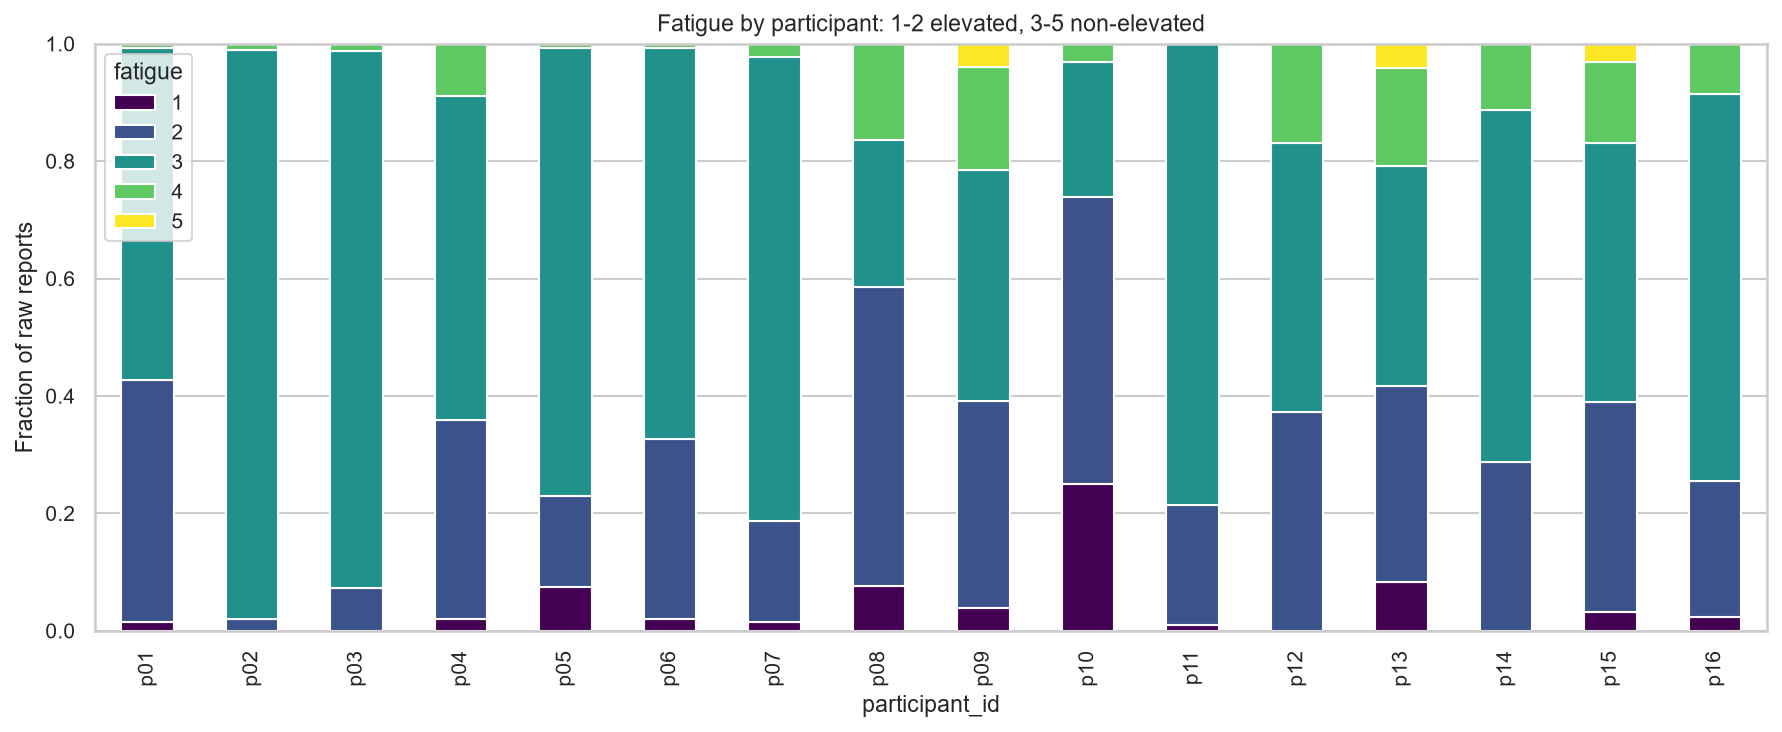

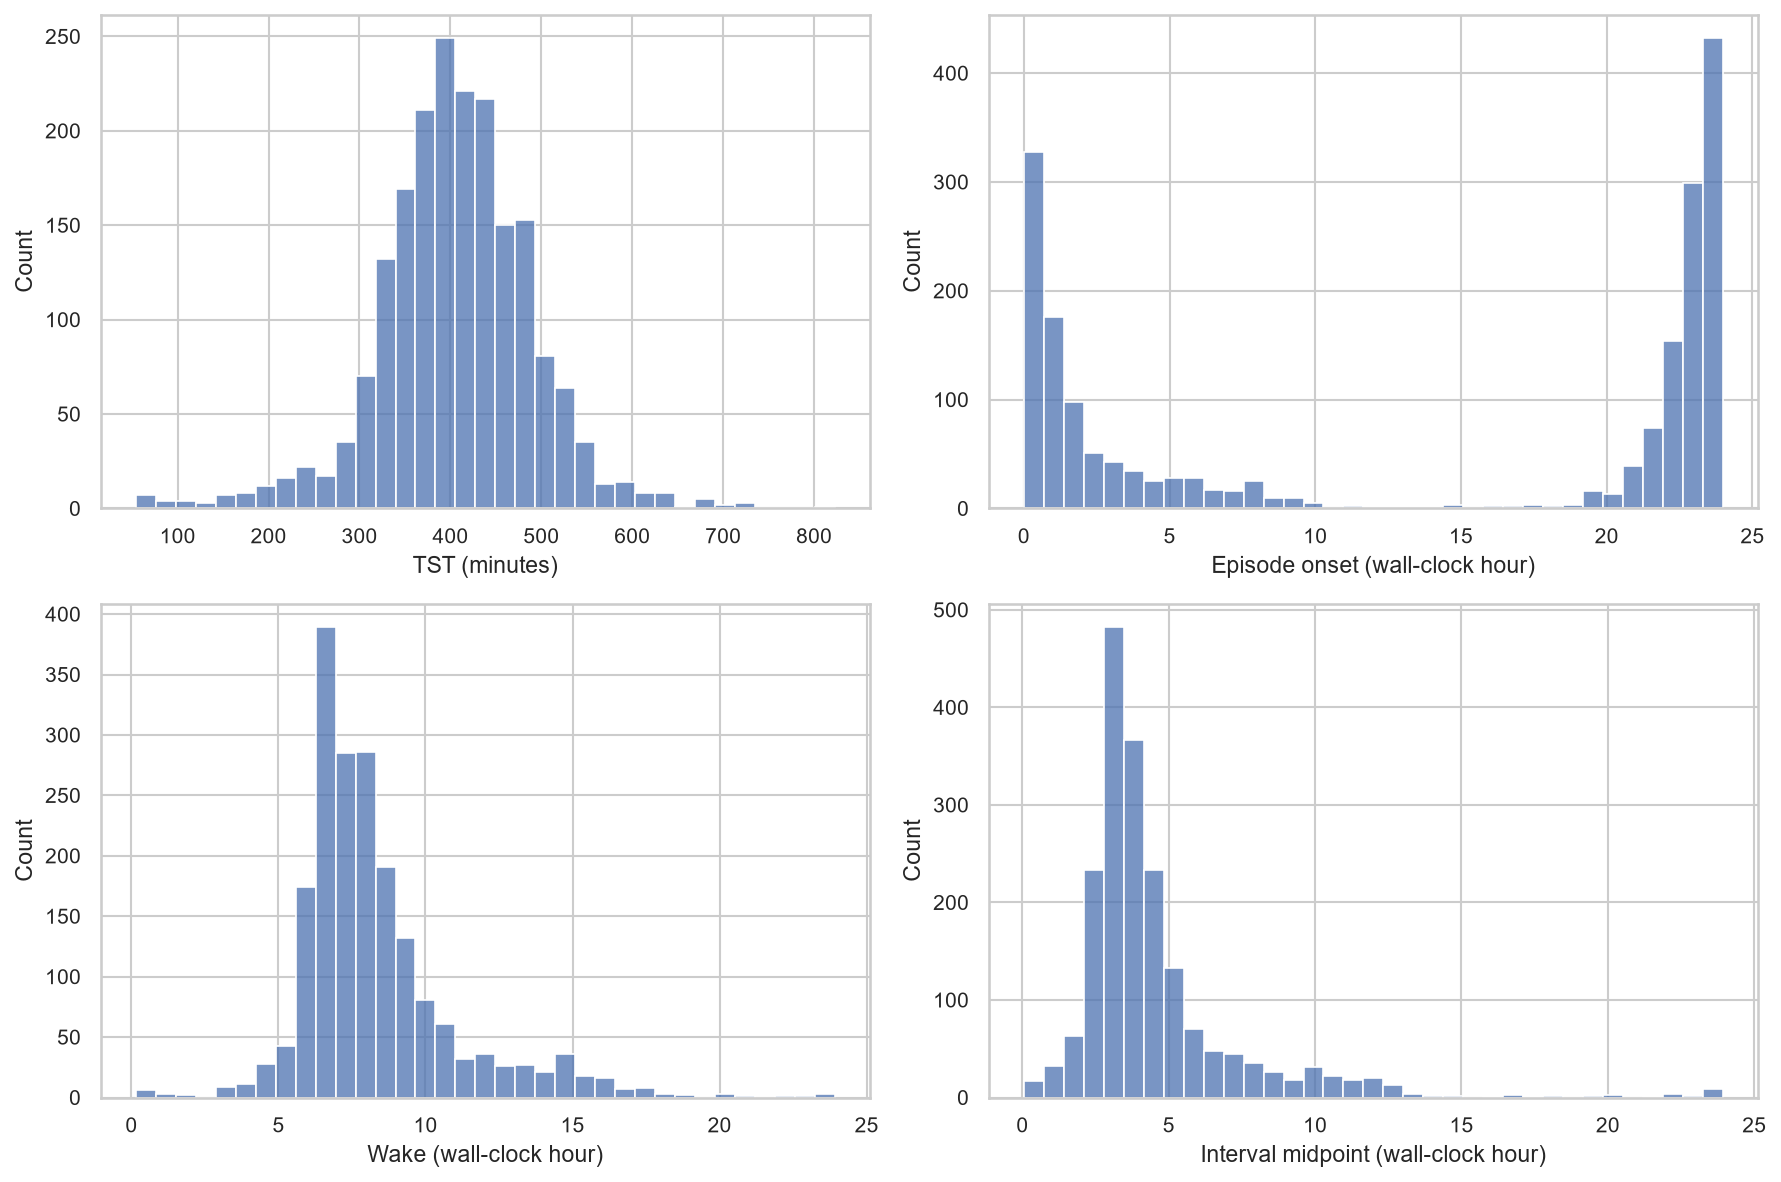

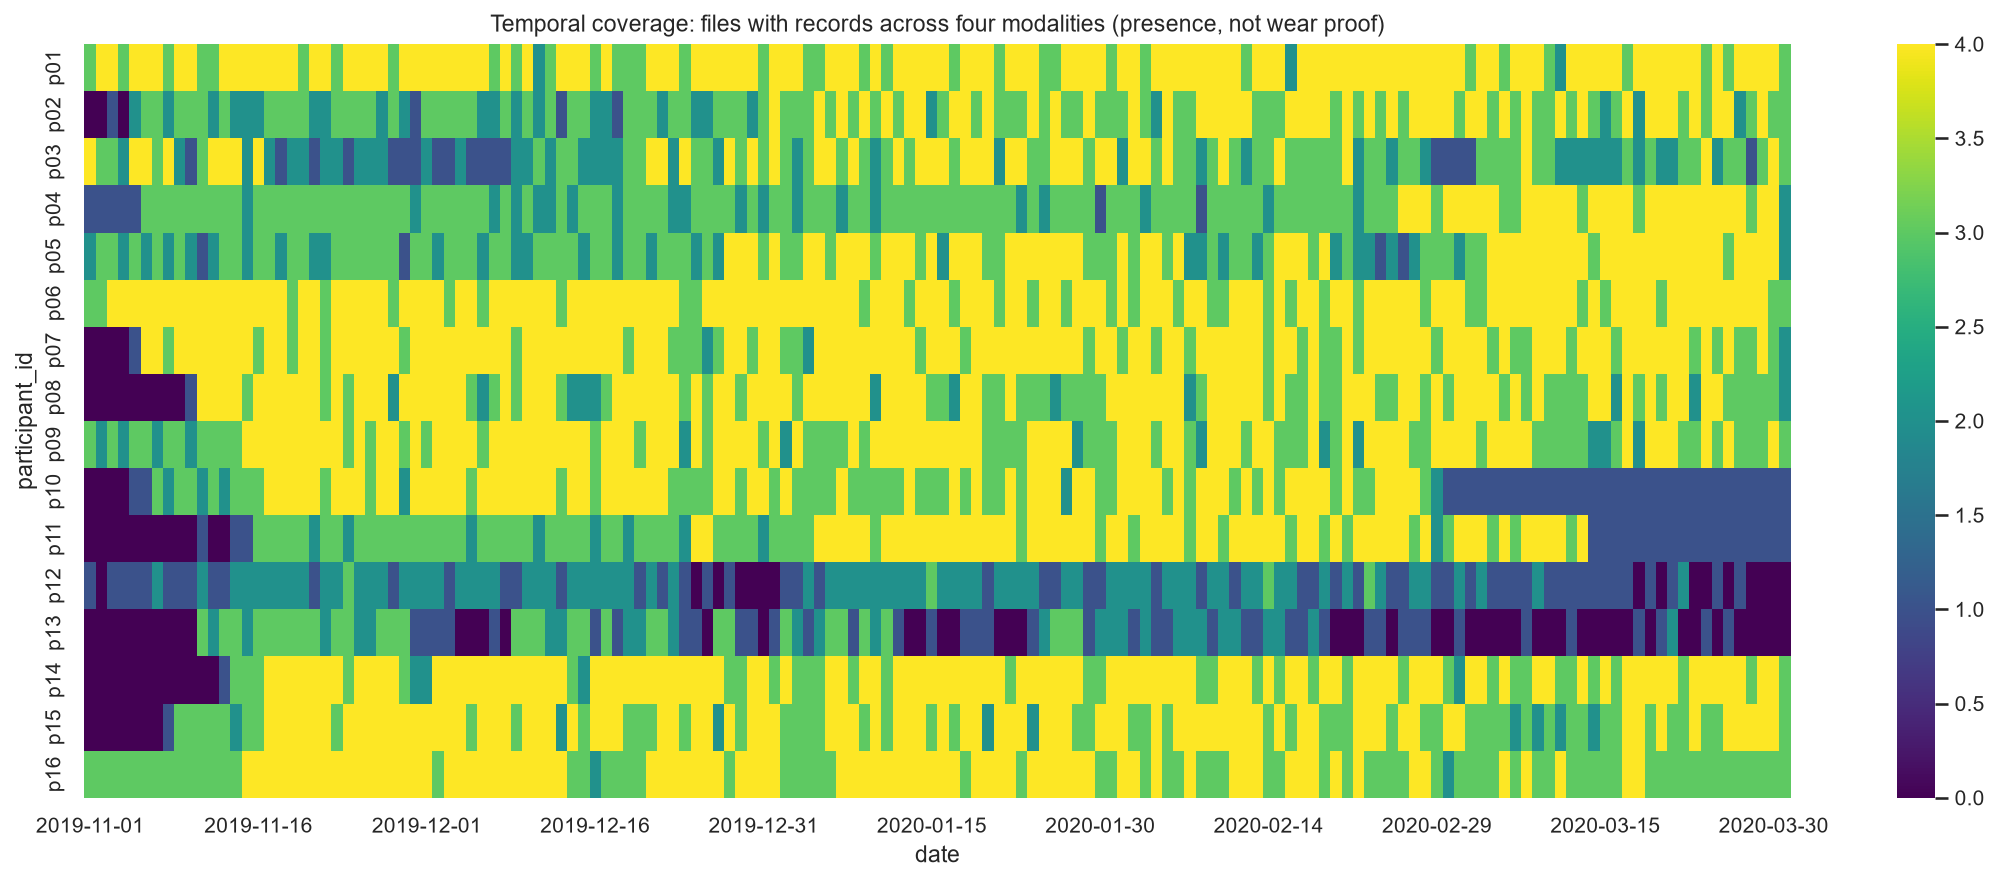

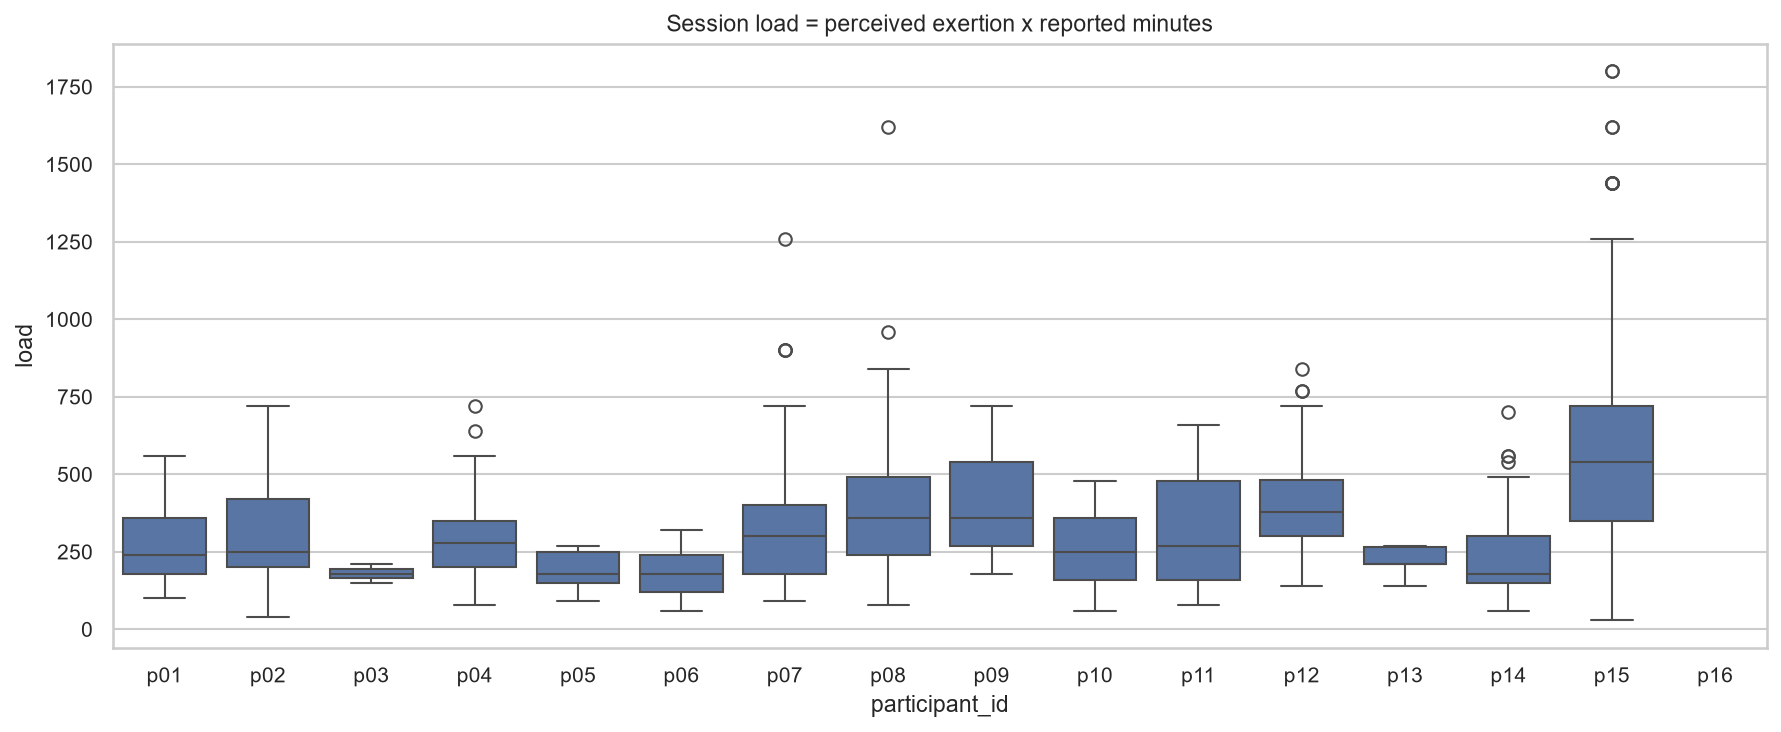

In [5]:
from IPython.display import Image, display
for name in ['participant_coverage.png','fatigue_by_participant.png','sleep_distributions.png','temporal_coverage.png','exercise_load.png']:
    p=ROOT/'reports/figures'/name
    if p.exists(): display(Image(filename=str(p)))

## Interpretation and handoff

Read `reports/target_audit.md`, `reports/data_audit_report.md` and `research/recommended_ml_spec.md`. Fatigue is a subjective wellness proxy; wearable TST is an estimate. Schedule alignment is not biological circadian phase. Final local-cutoff counts require timezone/availability decisions. Do not impute targets, use future baselines, train models in this notebook or upload participant-level outputs.